In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from timeit import timeit
url = "https://raw.githubusercontent.com/jakevdp/data-CDCbirths/master/births.csv"
births = pd.read_csv(url)
print(births.head())
print("Shape:", births.shape)
print(births.dtypes)
print(births.head())

   year  month  day gender  births
0  1969      1  1.0      F    4046
1  1969      1  1.0      M    4440
2  1969      1  2.0      F    4454
3  1969      1  2.0      M    4548
4  1969      1  3.0      F    4548
Shape: (15547, 5)
year        int64
month       int64
day       float64
gender        str
births      int64
dtype: object
   year  month  day gender  births
0  1969      1  1.0      F    4046
1  1969      1  1.0      M    4440
2  1969      1  2.0      F    4454
3  1969      1  2.0      M    4548
4  1969      1  3.0      F    4548


gender         F         M
decade                    
1960     1753634   1846572
1970    16263075  17121550
1980    18310351  19243452
1990    19479454  20420553
2000    18229309  19106428
        M/F Ratio  Male Excess (%)
decade                            
1960     1.052997         5.299738
1970     1.052787         5.278676
1980     1.050960         5.096030
1990     1.048312         4.831239
2000     1.048116         4.811587
Male births higher in every decade: True


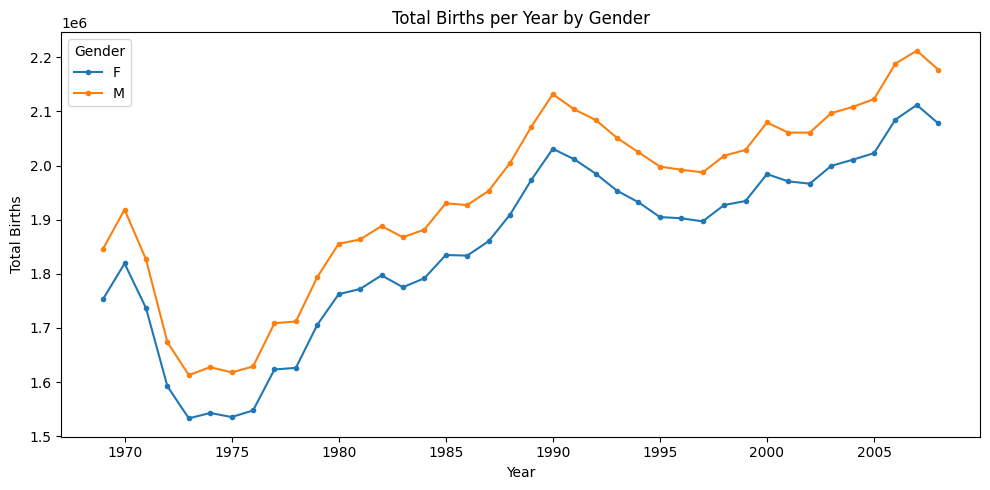

In [2]:
births["decade"] = 10 * (births["year"] // 10)
decade_gender = births.pivot_table(values="births",index="decade",columns="gender",aggfunc="sum")

print(decade_gender)

ratio = decade_gender["M"] / decade_gender["F"]

percent_excess = (
    (decade_gender["M"] - decade_gender["F"])
    / decade_gender["F"] * 100
)

print(pd.DataFrame({
    "M/F Ratio": ratio,
    "Male Excess (%)": percent_excess
}))

print(
    "Male births higher in every decade:",
    (decade_gender["M"] > decade_gender["F"]).all()
)

year_gender = births.pivot_table(
    values="births",
    index="year",
    columns="gender",
    aggfunc="sum"
)

year_gender.plot(figsize=(10, 5), marker=".")

plt.title("Total Births per Year by Gender")
plt.xlabel("Year")
plt.ylabel("Total Births")
plt.legend(title="Gender")
plt.tight_layout()
plt.show()

In [3]:
Q1, Q3 = np.percentile(births["births"], [25, 75])

mu = births["births"].median()

sig = 0.74 * (Q3 - Q1)

before = len(births)

clean = births.query(
    "births >= @mu - 5*@sig and births <= @mu + 5*@sig"
).copy()

removed = before - len(clean)

print("Q1:", Q1)
print("Q3:", Q3)
print("Robust Mean:", mu)
print("Robust Standard Deviation:", sig)
print("Rows before cleaning:", before)
print("Rows after cleaning:", len(clean))
print("Rows removed:", removed)

clean["day"] = clean["day"].astype(int)

Q1: 4358.0
Q3: 5289.5
Robust Mean: 4814.0
Robust Standard Deviation: 689.31
Rows before cleaning: 15547
Rows after cleaning: 14610
Rows removed: 937


decade            1960         1970         1980
dayofweek                                       
0          5063.826923  4689.097701  5276.907249
1          5286.096154  4885.252399  5503.842553
2          5074.622642  4750.376200  5367.642553
3          4978.288462  4696.923372  5333.485106
4          5107.884615  4782.095785  5393.087234
5          4651.057692  4207.784483  4483.901064
6          4342.346154  3979.278736  4308.120469


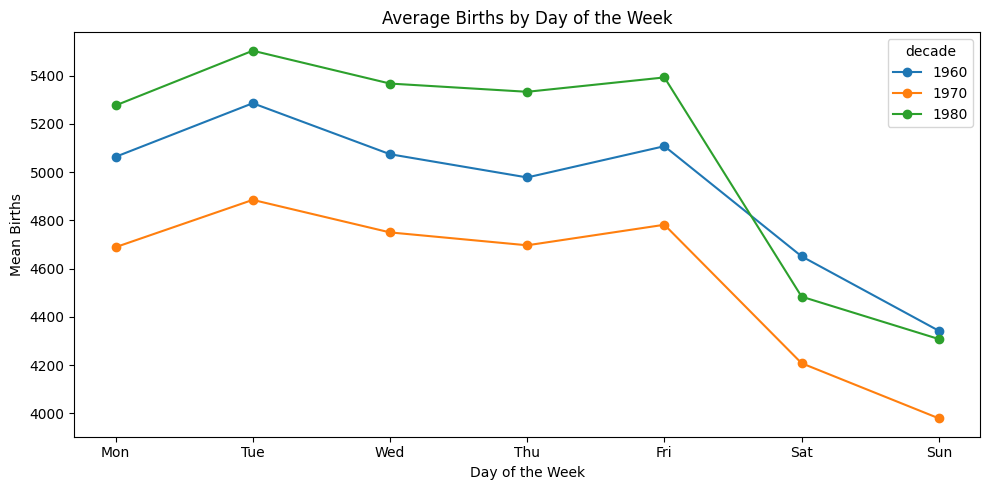

In [4]:
clean["date"] = pd.to_datetime(
    clean[["year", "month", "day"]]
)

clean = clean.set_index("date").sort_index()

clean["dayofweek"] = clean.index.dayofweek

clean["decade"] = 10 * (clean["year"] // 10)

weekday_table = clean.pivot_table(
    values="births",
    index="dayofweek",
    columns="decade",
    aggfunc="mean"
)

print(weekday_table)

weekday_table.plot(figsize=(10, 5), marker="o")

plt.xticks(
    range(7),
    ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
)

plt.title("Average Births by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Mean Births")
plt.tight_layout()
plt.show()

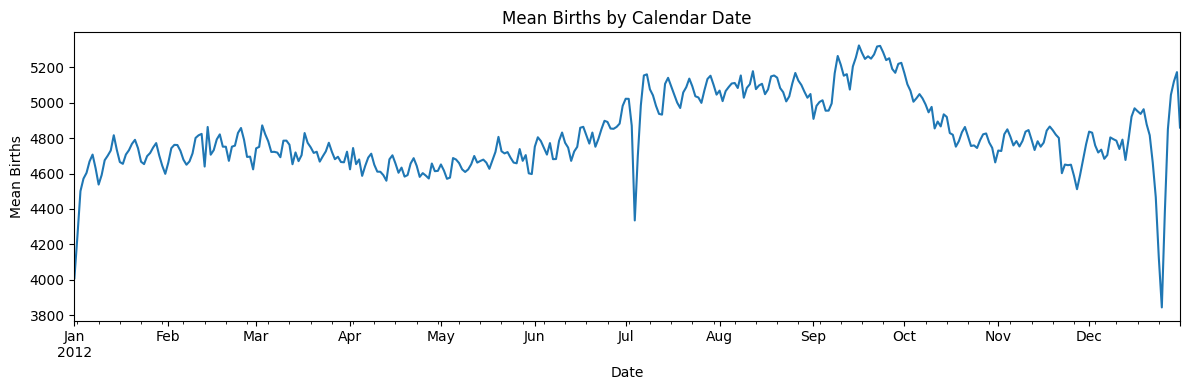

In [5]:
calendar_births = clean.pivot_table(
    values="births",
    index=["month", "day"],
    aggfunc="mean"
)

calendar_births = calendar_births.reset_index()

calendar_births["date"] = pd.to_datetime({
    "year": 2012,
    "month": calendar_births["month"],
    "day": calendar_births["day"]
})

calendar_births = calendar_births.sort_values(
    "date"
).set_index("date")

calendar_births["births"].plot(figsize=(12, 4))

plt.title("Mean Births by Calendar Date")
plt.xlabel("Date")
plt.ylabel("Mean Births")
plt.tight_layout()
plt.show()

In [6]:
grouped = clean.reset_index().groupby(
    ["decade", "gender"]
)["births"].sum().unstack()

pivot_clean = clean.reset_index().pivot_table(
    values="births",
    index="decade",
    columns="gender",
    aggfunc="sum"
)

print("Tables match:", grouped.equals(pivot_clean))
print(grouped)

data_for_time = clean.reset_index()

pivot_time = timeit(
    lambda: data_for_time.pivot_table(
        values="births",
        index="decade",
        columns="gender",
        aggfunc="sum"
    ),
    number=100
) / 100

group_time = timeit(
    lambda: data_for_time.groupby(
        ["decade", "gender"]
    )["births"].sum().unstack(),
    number=100
) / 100

timings = pd.DataFrame({
    "Method": ["pivot_table", "groupby + unstack"],
    "Average Time (seconds)": [pivot_time, group_time]
})

print(timings)

Tables match: True
gender         F         M
decade                    
1960     1752836   1845742
1970    16260348  17118785
1980    16336507  17171290
              Method  Average Time (seconds)
0        pivot_table                0.020180
1  groupby + unstack                0.012389


Five dates with the lowest mean births:
            month  day    births
date                            
2012-12-25     12   25  3844.450
2012-01-01      1    1  4009.225
2012-12-24     12   24  4126.250
2012-01-02      1    2  4247.400
2012-07-04      7    4  4335.325


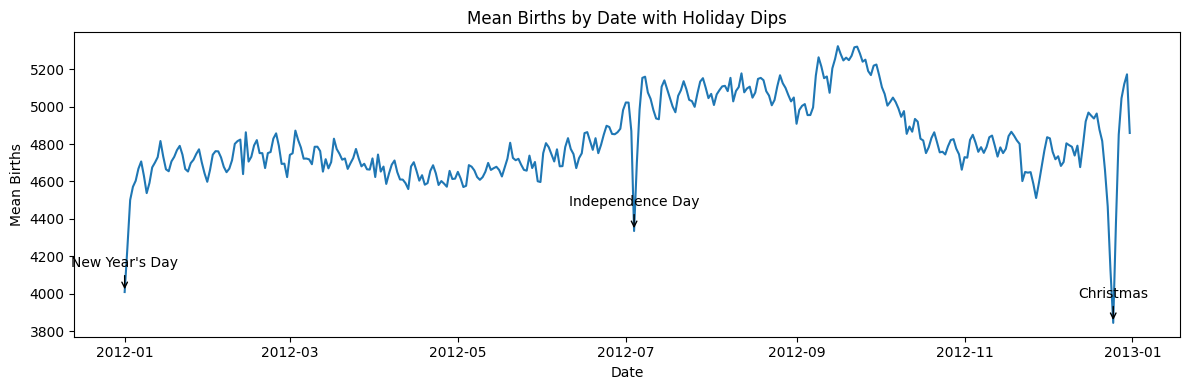

In [7]:
lowest_five = calendar_births.nsmallest(5, "births")

print("Five dates with the lowest mean births:")
print(lowest_five[["month", "day", "births"]])

holiday_labels = {
    "2012-01-01": "New Year's Day",
    "2012-07-04": "Independence Day",
    "2012-12-25": "Christmas"
}

fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(calendar_births.index, calendar_births["births"])

ax.set_title("Mean Births by Date with Holiday Dips")
ax.set_xlabel("Date")
ax.set_ylabel("Mean Births")

for date_text, label in holiday_labels.items():
    date = pd.Timestamp(date_text)

    if date in calendar_births.index:
        y = calendar_births.loc[date, "births"]

        ax.annotate(
            label,
            xy=(date, y),
            xytext=(0, 18),
            textcoords="offset points",
            ha="center",
            arrowprops={"arrowstyle": "->"}
        )

plt.tight_layout()
plt.show()